# 06 — Búsqueda de patrones: el triage total contra los factores externos

## Qué contesta este cuaderno

Una sola pregunta, en su versión exploratoria: **¿qué factores externos se mueven junto con
el conteo total de triages, y cuáles no?** El objetivo del proyecto es anticipar *cuándo sube
la tendencia del triage de urgencias*; antes de modelar hay que ver qué variables tienen
algo que decir.

1. **La serie con su historia al lado.** ¿Qué pasó en Manizales cuando la serie se movió?
2. **Qué queda por explicar** después de quitar el calendario.
3. **Mapa de correlaciones con rezago** contra todas las variables externas disponibles.
4. **La demanda de la ciudad** contra la del hospital.
5. **La Feria de Manizales.**
6. **El clima**: nivel y cambio brusco.
7. **Catástrofes.**

## Cómo leerlo

**Todo aquí es exploratorio.** Sirve para *generar* hipótesis, no para confirmarlas. Una
correlación que aparece aquí **no** cuenta como hallazgo hasta que la variable se
preregistre en `patrones/datos/variables.csv` y se pruebe fuera de muestra contra el control
de calendario (reglas del `CLAUDE.md`). Cada figura va con su lectura y sus límites.

## De dónde salen los datos

Todo son agregados versionados en el repositorio; el cuaderno no se conecta a ninguna base.

| Dato | Archivo | Fuente |
|---|---|---|
| Triage diario del SES Hospital Universitario de Caldas | `salidas/triage_diario.parquet` | base del hospital (agregado) |
| Festivos, puentes, vacaciones | `calendarios/calendario_Colombia.csv` | calendario oficial |
| Clima diario | `calendarios/clima_unificado.csv.gz` | IDEAM, METAR, Open-Meteo, NASA |
| Vigilancia semanal de Manizales | `calendarios/vigilancia_sivigila*.csv.gz` | microdatos SIVIGILA, INS |
| Consultas por institución | `calendarios/vigilancia_sivigila_instituciones.csv.gz` | SIVIGILA 995 |
| Eventos y desastres | `calendarios/eventos_…csv`, `desastres_…csv` | calendarios manuales (a reemplazar) |

**El hospital en el SIVIGILA es `170010010301` «SERVICIOS ESPECIALES DE SALUD».** Se excluye
de las consultas de la ciudad para que la variable externa no contenga al propio hospital.


In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "CLAUDE.md").exists())
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.dates as mdates

# Paleta de referencia (dataviz): categoricos en orden fijo, divergente azul-gris-rojo.
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUPERFICIE = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
DIVERGENTE = LinearSegmentedColormap.from_list("div", [AZUL, "#f0efec", ROJO])
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUDO,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TINTA,
    "font.size": 10, "lines.linewidth": 1.6, "legend.frameon": False,
})

FIN = "2026-09-20"      # el 21 esta incompleto
SES = 170010010301      # el hospital en SIVIGILA

# ---------- triage diario. Un dia SIN filas en el total no es "cero consultas": es una caida
# del registro (el hospital nunca cierra urgencias). Queda como nulo, no como cero.
d = pd.read_parquet(RAIZ / "salidas" / "triage_diario.parquet")
d["dia"] = pd.to_datetime(d["dia"])
tri = d.set_index("dia")["triages"].asfreq("D").loc[:FIN].astype(float)

# ---------- calendario
CAL = ["es_festivo", "es_puente", "es_vispera_festivo", "es_post_festivo", "es_quincena",
       "es_vacaciones_escolares", "es_semana_santa", "es_temporada_navidad",
       "es_temporada_fin_anio", "es_regreso_colegio"]
cal = (pd.read_csv(RAIZ / "calendarios" / "calendario_Colombia.csv", parse_dates=["fecha"])
         .set_index("fecha")[CAL + ["dia_semana"]].apply(pd.to_numeric, errors="coerce").fillna(0))

# ---------- clima
clima = pd.read_csv(RAIZ / "calendarios" / "clima_unificado.csv.gz", parse_dates=["fecha"]).set_index("fecha")

# ---------- vigilancia (todos los archivos de series; el de instituciones aparte)
series = [pd.read_csv(p) for p in sorted((RAIZ / "calendarios").glob("vigilancia_sivigila*.csv.gz"))
          if "instituciones" not in p.name]
cols = ["evento", "fecha_inicio_semana", "ambito", "variable", "valor"]
vig = pd.concat([s[cols] for s in series if set(cols) <= set(s.columns)], ignore_index=True)
vig["fecha_inicio_semana"] = pd.to_datetime(vig["fecha_inicio_semana"])
inst = pd.read_csv(RAIZ / "calendarios" / "vigilancia_sivigila_instituciones.csv.gz",
                   parse_dates=["fecha_inicio_semana"])

eventos = pd.read_csv(RAIZ / "calendarios" / "eventos_manizales_2020_2026.csv")
desastres = pd.read_csv(RAIZ / "calendarios" / "desastres_manizales_2020_2026.csv")

print(f"triage: {tri.index.min():%Y-%m-%d} a {tri.index.max():%Y-%m-%d}, {int(tri.sum()):,} triages")
print(f"clima hasta {clima.index.max():%Y-%m-%d}; vigilancia {vig.fecha_inicio_semana.min():%Y} a "
      f"{vig.fecha_inicio_semana.max():%Y-%m-%d}; eventos SIVIGILA: {sorted(vig.evento.unique())}")


triage: 2020-01-01 a 2026-09-20, 433,298 triages
clima hasta 2026-08-28; vigilancia 2011 a 2025-12-28; eventos SIVIGILA: [113, 155, 300, 346, 348, 349, 356, 360, 365, 370, 380, 390, 400, 410, 412, 414, 452, 549, 620, 810, 813, 820, 825, 831, 850, 875, 995, 998]


In [2]:
# ---------- herramientas comunes
def semana_epi(s, como="sum"):
    """Agrega a semana epidemiologica (domingo a sabado) indexada por el domingo."""
    r = s.resample("W-SAT")
    out = getattr(r, como)()
    n = s.resample("W-SAT").count()
    out.index = out.index - pd.Timedelta(days=6)
    n.index = out.index
    return out, n

def ols_residuo(y, Z):
    Z = Z.astype(float)
    b, *_ = np.linalg.lstsq(Z.values, y.values, rcond=None)
    return pd.Series(y.values - Z.values @ b, index=y.index)

def efectos_anio(idx):
    return pd.get_dummies(pd.Index(idx.year, name="a"), prefix="a", drop_first=True).set_index(idx).astype(float)

def armonicos(idx, k=3):
    t = idx.dayofyear.values / 365.25
    return pd.DataFrame({f"{f}{h}": fn(2 * np.pi * h * t) for h in range(1, k + 1)
                         for f, fn in (("s", np.sin), ("c", np.cos))}, index=idx)

COVID = ("2020-03-15", "2022-02-28")   # fuera del ajuste; se muestra, no se modela

# ---------- residuo DIARIO: log(triages) sin calendario y sin el nivel de cada anio
D = pd.DataFrame({"n": tri}).join(cal)
D = D[(D.n > 0)]
ajuste = ~D.index.to_series().between(*COVID)
Zd = pd.concat([pd.get_dummies(D["dia_semana"].astype(int), prefix="dow", drop_first=True).astype(float),
                D[CAL], efectos_anio(D.index)], axis=1)
Zd.insert(0, "c", 1.0)
b, *_ = np.linalg.lstsq(Zd[ajuste].values.astype(float), np.log(D.n[ajuste]).values, rcond=None)
D["res"] = np.log(D.n) - Zd.values.astype(float) @ b          # residuo en log ~ % sobre lo esperado

# Caidas de registro: dias sin filas, o con menos del 40 % de lo esperado. Se excluyen.
sin_filas = tri.index[tri.isna()]
caidos = D.index[(D.res < np.log(0.40)) & ~D.index.to_series().between(*COVID)]   # en COVID la caida fue real
print("dias sin ninguna fila:", [f"{x:%Y-%m-%d}" for x in sin_filas])
print("dias con < 40 % de lo esperado (probable caida parcial):",
      {f"{x:%Y-%m-%d}": int(D.n[x]) for x in caidos})
tri_limpio = tri.copy(); tri_limpio[caidos] = np.nan
D = D.drop(caidos)
print(f"residuo diario (fuera de COVID): sd {D.res[~D.index.to_series().between(*COVID)].std():.3f}")

# ---------- residuo SEMANAL (solo semanas con los 7 dias validos)
tw, nd = semana_epi(tri_limpio)
tw = tw[nd == 7]
cw, _ = semana_epi(cal[CAL])
W = pd.DataFrame({"triage": tw}).join(cw)
W = W.loc["2022-03-06":FIN]
Zw = pd.concat([W[CAL], efectos_anio(W.index)], axis=1); Zw.insert(0, "c", 1.0)
W["res"] = ols_residuo(np.log(W.triage), Zw)                  # sin calendario ni nivel del anio
Zws = pd.concat([Zw, armonicos(W.index)], axis=1)
W["res_sin_estac"] = ols_residuo(np.log(W.triage), Zws)       # ademas, sin estacionalidad anual
print(f"{len(W)} semanas completas; sd residuo {W.res.std():.3f} "
      f"(sin estacionalidad {W.res_sin_estac.std():.3f})")


dias sin ninguna fila: ['2024-03-19', '2024-03-20']
dias con < 40 % de lo esperado (probable caida parcial): {'2024-03-21': 40}
residuo diario (fuera de COVID): sd 0.121
236 semanas completas; sd residuo 0.082 (sin estacionalidad 0.071)


---
# 1. La serie con su historia al lado

Media de triages por día en cada semana epidemiológica, 2020-2026, con los hechos de Manizales que ya están documentados en los calendarios y en `docs/CONTEXTO.md`.

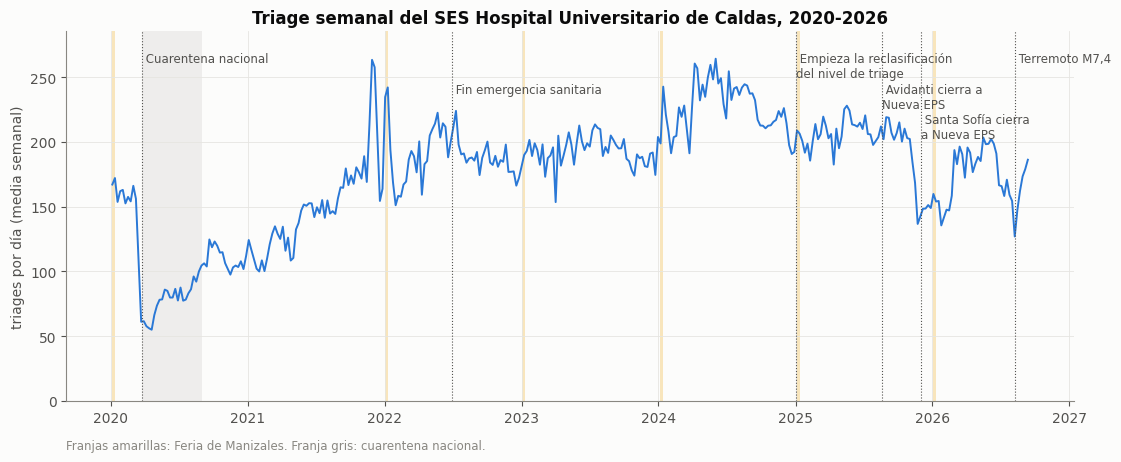

dia
2020    105.1
2021    149.5
2022    189.8
2023    192.9
2024    227.0
2025    199.1
2026    172.9


In [3]:
media_sem = (tw / 7)
hitos = [  # (fecha, texto, desplazamiento vertical)
    ("2020-03-25", "Cuarentena nacional", 0), ("2022-06-30", "Fin emergencia sanitaria", 1),
    ("2025-01-01", "Empieza la reclasificación\ndel nivel de triage", 0),
    ("2025-08-21", "Avidanti cierra a\nNueva EPS", 1), ("2025-12-01", "Santa Sofía cierra\na Nueva EPS", 2),
    ("2026-08-10", "Terremoto M7,4", 0)]
fig, ax = plt.subplots(figsize=(13, 4.8))
ferias = eventos[eventos.nombre_evento.eq("Feria de Manizales") & eventos.estado.eq("realizado")]
for _, r in ferias.iterrows():
    ax.axvspan(pd.Timestamp(r.fecha_inicio), pd.Timestamp(r.fecha_fin), color=AMARILLO, alpha=.25, lw=0)
ax.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-08-31"), color=MUDO, alpha=.12, lw=0)
ax.plot(media_sem.index, media_sem.values, color=AZUL, lw=1.4)
ymax = media_sem.max()
for f, t, k in hitos:
    x = pd.Timestamp(f)
    ax.axvline(x, color=TINTA2, lw=.8, ls=":")
    ax.text(x, ymax * (1.02 - .09 * k), " " + t, fontsize=8.5, color=TINTA2, va="top")
ax.set_ylabel("triages por día (media semanal)")
ax.set_title("Triage semanal del SES Hospital Universitario de Caldas, 2020-2026")
ax.text(0, -.13, "Franjas amarillas: Feria de Manizales. Franja gris: cuarentena nacional.",
        transform=ax.transAxes, fontsize=8.5, color=MUDO)
ax.set_ylim(0, ymax * 1.08)
plt.show()
print(media_sem.groupby(media_sem.index.year).mean().round(1).to_string())


## Lectura

**Los movimientos grandes de la serie no son del clima ni de las fiestas: son de COVID y del
propio sistema de salud.**

| 2020 | 2021 | 2022 | 2023 | 2024 | 2025 | 2026 |
|---|---|---|---|---|---|---|
| 105,1 | 149,5 | 189,8 | 192,9 | **227,0** | 199,1 | 172,9 |

- **La cuarentena** hunde la serie a ~60 triages por día. Tarda casi dos años en recuperarse.
- **La caída desde 2025** empieza justo cuando empieza la reclasificación del nivel de triage
  (`CONTEXTO.md`, 2026-09-22).
- **Desde el 21 de noviembre de 2025** el volumen baja de golpe, de ~200 a ~130 por día. Es
  diez días antes de que Santa Sofía cierre a Nueva EPS. **Eso es coincidencia en el tiempo,
  no prueba de nada**, pero es el tipo de hecho que ningún calendario actual registra.
- **El terremoto** del 10 de agosto de 2026 se ve como un pozo de dos semanas.
- **Cada Feria** cae al principio de enero, sobre el regreso de vacaciones. A simple vista no se
  distingue de ese regreso.

**Corrección de datos hecha en este cuaderno.** El 19 y el 20 de marzo de 2024 no tienen ni un
registro, y el 21 tiene 40. Es una caída del sistema de registro, no un día sin pacientes: un
servicio de urgencias no cierra. Esos días se tratan como **sin dato**. Antes contaban como
cero y fabricaban una semana de −42 %.

**Límite.** La figura es la media semanal: no ve lo que pasa dentro de la semana.

---
# 2. Qué queda por explicar

Residuo semanal: cuánto se aparta cada semana de lo que esperaría el calendario (festivos, puentes, vacaciones, Semana Santa, Navidad) **dentro de su propio año**. Es lo que una variable externa tendría que explicar. Se marcan las semanas por fuera de ±2 desviaciones.

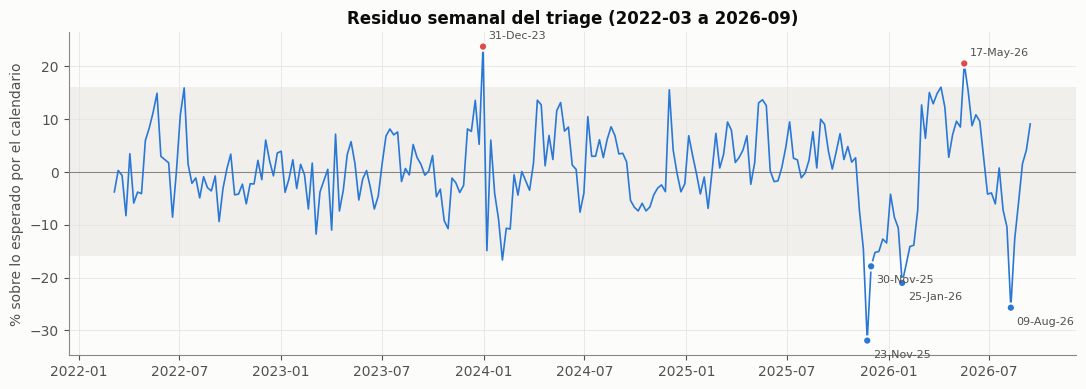

sd del residuo semanal: 8.0 %   ·   autocorrelación a 1 semana: +0.62


,% sobre lo esperado,qué pasaba (calendarios)
dia,,
2023-12-31,23.6,Feria de Manizales; Alumbrado Navideno Aguinal...
2026-05-17,20.4,1 festivo(s)
2026-04-05,15.9,Semana Santa
2022-07-10,15.8,Fiesta Virgen del Carmen; Fin emergencia sanit...
2024-12-01,15.4,Dia de las Velitas; Media Maraton de Manizales...
2026-05-24,15.2,—
2026-03-15,14.9,—
2022-05-22,14.8,—
2026-03-29,14.7,Semana Santa; 2 festivo(s)


In [4]:
r = W["res"]
pct = (np.exp(r) - 1) * 100
sd = pct.std()
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.axhspan(-2 * sd, 2 * sd, color="#f0efec", lw=0)
ax.axhline(0, color=MUDO, lw=.8)
ax.plot(pct.index, pct.values, color=AZUL, lw=1.2)
extremos = pct[pct.abs() > 2 * sd]
extremos = extremos.reindex(extremos.abs().sort_values(ascending=False).index[:6])
ax.scatter(extremos.index, extremos.values, s=36, color=[ROJO if v > 0 else AZUL for v in extremos],
           edgecolor=SUPERFICIE, lw=1.5, zorder=3)
for x, v in extremos.items():
    ax.annotate(f"{x:%d-%b-%y}", (x, v), textcoords="offset points", xytext=(4, 6 if v > 0 else -12),
                fontsize=8, color=TINTA2)
ax.set_ylabel("% sobre lo esperado por el calendario")
ax.set_title("Residuo semanal del triage (2022-03 a 2026-09)")
plt.show()

def que_paso(sem):
    fin = sem + pd.Timedelta(days=6)
    txt = []
    for _, e in eventos.dropna(subset=["fecha_inicio"]).iterrows():
        a, b_ = pd.Timestamp(e.fecha_inicio), pd.Timestamp(e.fecha_fin if pd.notna(e.fecha_fin) else e.fecha_inicio)
        if a <= fin and b_ >= sem: txt.append(e.nombre_evento)
    for _, e in desastres.iterrows():
        a, b_ = pd.Timestamp(e.fecha_inicio), pd.Timestamp(e.fecha_fin)
        if a <= fin and b_ >= sem and (b_ - a).days <= 14: txt.append(f"{e.tipo_evento} ({e.municipio})")
    for f, t, _ in hitos:
        if sem - pd.Timedelta(days=21) <= pd.Timestamp(f) <= fin: txt.append(t.replace("\n", " "))
    fest = int(W.loc[sem, "es_festivo"]) if sem in W.index else 0
    if fest: txt.append(f"{fest} festivo(s)")
    return "; ".join(dict.fromkeys(txt)) or "—"

tabla = pd.DataFrame({"% sobre lo esperado": pct.round(1)})
orden = pd.concat([tabla.nlargest(10, "% sobre lo esperado"), tabla.nsmallest(10, "% sobre lo esperado")])
orden["qué pasaba (calendarios)"] = [que_paso(i) for i in orden.index]
orden.index = orden.index.strftime("%Y-%m-%d")
print(f"sd del residuo semanal: {sd:.1f} %   ·   autocorrelación a 1 semana: {r.autocorr():+.2f}")
orden


## Lectura

**Lo que el calendario no explica es un 8,0 % semanal, y no es ruido: viene en bloques.**

- **La autocorrelación del residuo a una semana es de +0,62.** Si una semana va por encima
  de lo esperado, la siguiente suele ir igual. Lo que falta por explicar se mueve **lento**:
  semanas o meses seguidos, no sacudidas de un día. Eso apunta a variables de **nivel** que
  cambian despacio (la red de servicios, la afiliación, una temporada), más que a eventos de
  un día.
- **Las semanas extremas se agrupan.** De las 10 más bajas, 7 caen entre noviembre de 2025 y
  febrero de 2026, y otra es la del terremoto. Hay además un bloque alto de marzo a mayo de
  2026 (+15 a +20 %).
- **La columna «qué pasaba» sale casi toda vacía.** Los calendarios que hay hoy no tienen nada
  que decir de la mayoría de las semanas extremas. **Ahí está el hueco de información**: no en
  el clima, sino en lo que le pasa a la red de salud de Manizales.
- **La semana más alta (31-dic-2023, +23,6 %)** junta Año Nuevo con el arranque de la Feria de
  2024. Puede ser un efecto real o un control de fin de año mal ajustado; no se distingue.

**Límite.** El residuo quita el nivel de cada año. Por eso la caída de 2025 frente a 2024 no
aparece aquí: aparece en la figura 1. Lo que se ve es lo que se mueve **dentro** de cada año.

---
# 3. Mapa de correlaciones con rezago

Cada fila es una variable externa; cada columna, cuántas semanas **antes** del triage se mide (0 = la misma semana; −1 = la semana *después*, que sirve de control: una variable que "predice" hacia atrás en el tiempo está compartiendo otra cosa, no causando).

Dos paneles: **(a)** dentro de cada año, con la estacionalidad; **(b)** quitando además la estacionalidad anual de ambas series. Lo que sobrevive en (b) no es solo "las dos cosas suben en mayo". El punto negro marca |r| por encima del umbral aproximado de significación, corregido por autocorrelación (Bartlett).

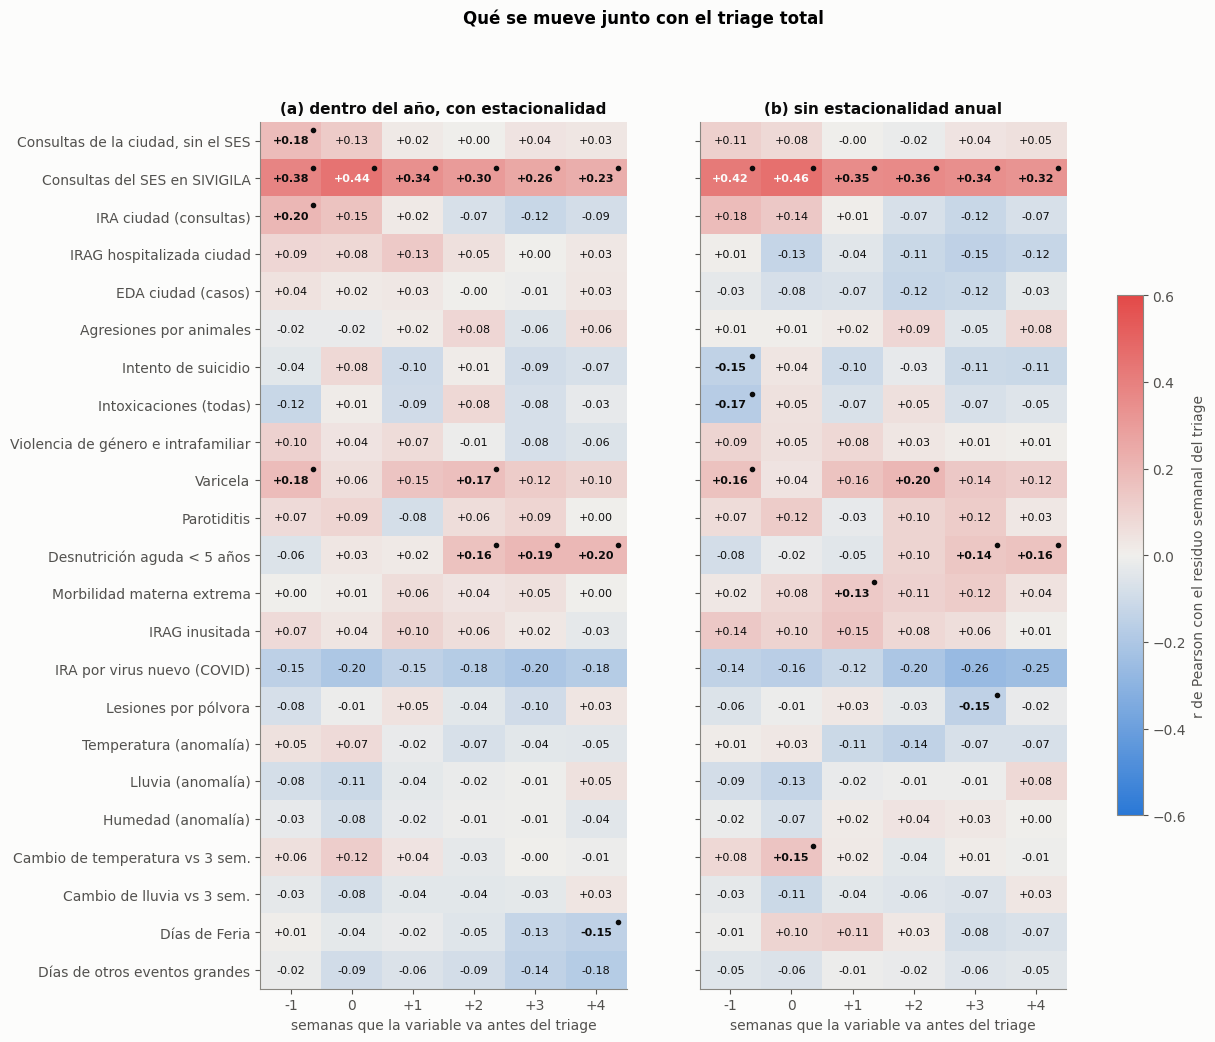

(a): 14 celdas marcadas de 138 pruebas; por azar se esperarian ~7
(b): 15 celdas marcadas de 138 pruebas; por azar se esperarian ~7
marcadas en (b): [('Consultas del SES en SIVIGILA', -1, 0.42), ('Consultas del SES en SIVIGILA', 0, 0.46), ('Consultas del SES en SIVIGILA', 1, 0.35), ('Consultas del SES en SIVIGILA', 2, 0.36), ('Consultas del SES en SIVIGILA', 3, 0.34), ('Consultas del SES en SIVIGILA', 4, 0.32), ('Intento de suicidio', -1, -0.15), ('Intoxicaciones (todas)', -1, -0.17), ('Varicela', -1, 0.16), ('Varicela', 2, 0.2), ('Desnutrición aguda < 5 años', 3, 0.14), ('Desnutrición aguda < 5 años', 4, 0.16), ('Morbilidad materna extrema', 1, 0.13), ('Lesiones por pólvora', 3, -0.15), ('Cambio de temperatura vs 3 sem.', 0, 0.15)]
semanas con dato por variable:
Consultas de la ciudad, sin el SES     199
Consultas del SES en SIVIGILA          198
IRA ciudad (consultas)                 199
IRAG hospitalizada ciudad              199
EDA ciudad (casos)                     199
Agresiones 

In [5]:
# ---------- variables externas semanales
ext = pd.DataFrame(index=W.index)

man = vig[vig.ambito.eq("manizales")].pivot_table(index="fecha_inicio_semana",
                                                  columns=["evento", "variable"], values="valor", aggfunc="sum")
def serie_vig(ev, var):
    return man[(ev, var)] if (ev, var) in man.columns else None

ciudad = inst[inst.cod_upgd.ne(SES)].groupby("fecha_inicio_semana")["consultas_todas_causas"].sum()
ext["Consultas de la ciudad, sin el SES"] = np.log(ciudad.replace(0, np.nan))
ext["Consultas del SES en SIVIGILA"] = np.log(inst[inst.cod_upgd.eq(SES)].groupby("fecha_inicio_semana")
                                              ["consultas_todas_causas"].sum().replace(0, np.nan))
ext["IRA ciudad (consultas)"] = np.log(serie_vig(995, "consultas_ira_total"))
ext["IRAG hospitalizada ciudad"] = np.log1p(serie_vig(995, "hospitalizaciones_irag_total"))
ext["EDA ciudad (casos)"] = np.log(serie_vig(998, "casos_eda_total"))
# otros eventos SIVIGILA (casos ocurridos en Manizales). Solo los que pueden llegar a una
# urgencia; quedan fuera cancer (155), tuberculosis (810-825), VIH (850) y las intoxicaciones
# por tipo (360-414), que ya estan sumadas en el 365.
NOMBRES = {300: "Agresiones por animales", 356: "Intento de suicidio", 365: "Intoxicaciones (todas)",
           875: "Violencia de género e intrafamiliar", 831: "Varicela", 620: "Parotiditis",
           113: "Desnutrición aguda < 5 años", 549: "Morbilidad materna extrema",
           348: "IRAG inusitada", 346: "IRA por virus nuevo (COVID)", 452: "Lesiones por pólvora"}
for ev, nombre in NOMBRES.items():
    s = serie_vig(ev, "casos_ocurrencia")
    if s is not None and s.sum() > 0:
        ext[nombre] = np.log1p(s)

# clima: anomalia contra el mismo mes, y cambio contra las 3 semanas previas
cl = pd.DataFrame({"t": semana_epi(clima["temp_media_consenso"], "mean")[0],
                   "p": semana_epi(clima["precip_consenso_mm"], "sum")[0],
                   "h": semana_epi(clima["humedad_consenso"], "mean")[0]})
z = cl.groupby(cl.index.month).transform(lambda s: (s - s.mean()) / s.std())
ext["Temperatura (anomalía)"] = z.t
ext["Lluvia (anomalía)"] = z.p
ext["Humedad (anomalía)"] = z.h
ext["Cambio de temperatura vs 3 sem."] = z.t - z.t.shift(1).rolling(3).mean()
ext["Cambio de lluvia vs 3 sem."] = z.p - z.p.shift(1).rolling(3).mean()

# eventos sociales (dias por semana)
def dias_de(filtro):
    s = pd.Series(0.0, index=pd.date_range("2020-01-01", FIN))
    for _, e in eventos[filtro].dropna(subset=["fecha_inicio"]).iterrows():
        s.loc[e.fecha_inicio: (e.fecha_fin if pd.notna(e.fecha_fin) else e.fecha_inicio)] = 1
    return semana_epi(s)[0]
ok = eventos.estado.isin(["realizado", "hibrido"])
ext["Días de Feria"] = dias_de(ok & eventos.nombre_evento.eq("Feria de Manizales"))
ext["Días de otros eventos grandes"] = dias_de(ok & ~eventos.nombre_evento.eq("Feria de Manizales")
                                               & eventos.categoria.isin(["teatro", "musical", "civico", "taurino", "deportivo"]))
ext = ext.loc[W.index.min():]

# ---------- quitar el nivel de cada anio (y en (b) tambien la estacionalidad) a cada variable
def limpiar(s, estac):
    s = s.dropna()
    if s.std() == 0 or len(s) < 30: return s * np.nan
    Z = pd.concat([cw.reindex(s.index).fillna(0), efectos_anio(s.index)], axis=1); Z.insert(0, "c", 1.0)
    if estac: Z = pd.concat([Z, armonicos(s.index)], axis=1)
    return ols_residuo(s, Z)

LAGS = [-1, 0, 1, 2, 3, 4]
def mapa(estac):
    y = W["res_sin_estac" if estac else "res"]
    R, S = pd.DataFrame(index=ext.columns, columns=LAGS, dtype=float), pd.DataFrame(index=ext.columns, columns=LAGS, dtype=bool)
    for c in ext.columns:
        x = limpiar(ext[c], estac)
        for L in LAGS:
            par = pd.concat([y, x.shift(L)], axis=1).dropna()
            if len(par) < 30: continue
            r_ = par.iloc[:, 0].corr(par.iloc[:, 1])
            a1, a2 = par.iloc[:, 0].autocorr(), par.iloc[:, 1].autocorr()
            neff = len(par) * (1 - a1 * a2) / (1 + a1 * a2)
            R.loc[c, L], S.loc[c, L] = r_, abs(r_) > 1.96 / np.sqrt(max(neff - 3, 4))
    return R, S

(Ra, Sa), (Rb, Sb) = mapa(False), mapa(True)
fig, axes = plt.subplots(1, 2, figsize=(13, 0.42 * len(ext.columns) + 1.6), sharey=True)
for ax, R, S, t in [(axes[0], Ra, Sa, "(a) dentro del año, con estacionalidad"),
                    (axes[1], Rb, Sb, "(b) sin estacionalidad anual")]:
    im = ax.imshow(R.values.astype(float), cmap=DIVERGENTE, vmin=-.6, vmax=.6, aspect="auto")
    ax.set_xticks(range(len(LAGS)), [f"{L:+d}" if L else "0" for L in LAGS])
    ax.set_yticks(range(len(R)), R.index)
    ax.set_xlabel("semanas que la variable va antes del triage")
    ax.set_title(t, fontsize=11); ax.grid(False)
    for i in range(R.shape[0]):
        for j in range(R.shape[1]):
            v = R.iat[i, j]
            if pd.isna(v): continue
            ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=8,
                    color=TINTA if abs(v) < .4 else SUPERFICIE, fontweight="bold" if S.iat[i, j] else "normal")
            if S.iat[i, j]:
                ax.plot(j + .36, i - .28, "o", ms=3, color=TINTA)
fig.colorbar(im, ax=axes, shrink=.6, label="r de Pearson con el residuo semanal del triage")
fig.suptitle("Qué se mueve junto con el triage total", fontweight="bold", x=.42)
plt.show()
for nom, S_ in [("(a)", Sa), ("(b)", Sb)]:
    k_ = int(S_.values.sum()); n_ = int(Ra.notna().values.sum())
    print(f"{nom}: {k_} celdas marcadas de {n_} pruebas; por azar se esperarian ~{0.05*n_:.0f}")
print("marcadas en (b):", [(i, c, round(Rb.loc[i, c], 2)) for i in Rb.index for c in LAGS if Sb.loc[i, c]])
n_par = pd.concat([W.res, ext], axis=1).notna().sum()
print("semanas con dato por variable:\n" + n_par.drop("res").to_string())


## Lectura

> **Corrección del 2026-09-28.** Este mapa correlaciona el residuo **semanal** después de quitar la estacionalidad. Eso borra los efectos que se repiten cada año en las mismas fechas, diluye los de pocos días y no ve los cambios bruscos ni los subgrupos. «Casi nada se mueve» es verdad **para este método**, no para el hospital. Los mismos factores, medidos con su propio reloj, sí dejan huella: ver `07_mecanismos.ipynb`.

**Con este método, casi nada se mueve con el triage total.** Casi todas las correlaciones están entre −0,15 y
+0,15. Hay **15 celdas marcadas de 138 pruebas, y el puro azar daría unas 7**: como mucho, un
puñado de ellas es real, y no se sabe cuáles. Nada de este mapa cuenta como hallazgo hasta
preregistrarlo y probarlo fuera de muestra.

Lo que se puede decir con cuidado:

1. **El método sí encuentra una relación cuando existe.** Las consultas del propio SES
   reportadas al SIVIGILA correlacionan **+0,32 a +0,46** con su triage, en todos los rezagos
de (b). Es la misma
   institución: es la prueba de control, no un hallazgo.
2. **La demanda del resto de la ciudad apenas acompaña**: +0,08 a +0,18. Se ve más en la
   sección 4.
3. **El clima no aparece.** Ninguna variable de nivel pasa de ±0,15. El **cambio** de
   temperatura de la misma semana da +0,15 en (b). La lluvia de la misma semana da −0,12 a
   −0,14: más lluvia, un poco menos de triage. Es el mismo signo que ya se había medido, y
   es débil.
4. **Los eventos sociales no aparecen** en cuanto se quita la estacionalidad. En (a) la Feria
   da −0,15 a +4 semanas; en (b) desaparece. Es el bajón de febrero, no la Feria.
5. **Tres señales débiles, para mirar después y no para creer:**
   - **Varicela**: +0,16 a +0,20. Aparece también en −1, o sea con la variable *después* del
     triage. Eso sugiere un factor común, probablemente el calendario escolar, más que una
     causa.
   - **Desnutrición aguda < 5 años**: +0,14 a +0,20 a 3-4 semanas.
   - **IRA por virus nuevo (COVID)**: −0,12 a −0,26 en todos los rezagos, pero solo con 104
     semanas (2022-2023). Puede ser el final del periodo pospandemia, no un efecto.
6. **Las celdas marcadas en −1** (intento de suicidio −0,15, intoxicaciones −0,17) son
   sospechosas por construcción: la variable va *después* del triage.

**Límites.**
- Correlación lineal y semanal.
- El SIVIGILA solo llega a 2025, así que el mapa cubre 2022-2025 (~200 semanas).
- El umbral de significación es aproximado: Bartlett, sin corrección por comparaciones
  múltiples.
- Correlación no es efecto: una variable externa puede moverse con el triage porque las dos
  dependen de una tercera.

---
# 4. La demanda de la ciudad contra la del hospital

Consultas semanales por todas las causas de las demás instituciones de Manizales (SIVIGILA 995, **sin el SES**) contra el triage del hospital. Las dos series van en **índice**: cada semana dividida por la media de su año, para compararlas en el mismo eje sin que el crecimiento de la red (instituciones que entran a notificar) se lleve la figura.

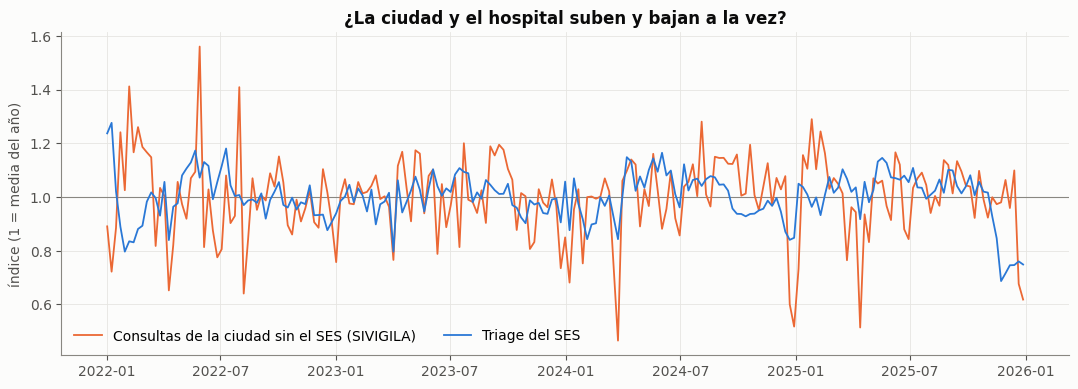

208 semanas 2022-2025
r en nivel (índice):          +0.165
r en cambio semana a semana:  +0.229
r del hospital con la ciudad L semanas antes: {-2: 0.097, -1: 0.078, 0: 0.165, 1: -0.0, 2: -0.056, 3: 0.02, 4: -0.0}


In [6]:
def indice(s):
    s = s.dropna()
    return s / s.groupby(s.index.year).transform("mean")
a = indice(ciudad.loc["2022-01-01":]); b_ = indice(tw.loc["2022-01-01":"2025-12-31"])
par = pd.concat([a.rename("ciudad"), b_.rename("hospital")], axis=1).dropna()
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.axhline(1, color=MUDO, lw=.8)
ax.plot(par.index, par.ciudad, color=NARANJA, lw=1.3, label="Consultas de la ciudad sin el SES (SIVIGILA)")
ax.plot(par.index, par.hospital, color=AZUL, lw=1.3, label="Triage del SES")
ax.set_ylabel("índice (1 = media del año)")
ax.set_title("¿La ciudad y el hospital suben y bajan a la vez?")
ax.legend(loc="lower left", ncol=2)
plt.show()
print(f"{len(par)} semanas 2022-2025")
print(f"r en nivel (índice):          {par.ciudad.corr(par.hospital):+.3f}")
print(f"r en cambio semana a semana:  {par.ciudad.diff().corr(par.hospital.diff()):+.3f}")
lag = {L: par.hospital.corr(par.ciudad.shift(L)) for L in range(-2, 5)}
print("r del hospital con la ciudad L semanas antes:", {k: round(v, 3) for k, v in lag.items()})


## Lectura

**El hospital no sube y baja con la ciudad.**
- En nivel, r = **+0,17**. En cambio semana a semana, r = +0,23.
- Con rezago, nada: la ciudad de la semana anterior no anticipa al hospital (r = 0,00).

**Por qué, al menos en parte.** El «total de consultas» del SIVIGILA suma **consulta externa y
urgencias**, y la consulta externa es programada. En las semanas festivas la serie de la
ciudad se desploma hasta 0,5 veces su media, porque cierran las agendas, mientras el triage
de urgencias casi no se mueve. Son dos demandas distintas. El total de la ciudad **no es una
medida de la demanda urgente** y, así como viene, no sirve de variable externa.

**Límite.** No hay en el SIVIGILA una columna que separe urgencias de consulta externa. Una
serie de urgencias de otras instituciones exigiría otra fuente: RIPS / SISPRO.

---
# 5. La Feria de Manizales

Residuo **diario** (sin día de la semana, festivos, temporada de fin de año ni nivel del año) alrededor del primer día de cada Feria. Cada línea gris es un año; la azul, la media. La franja amarilla es la duración típica de la Feria.

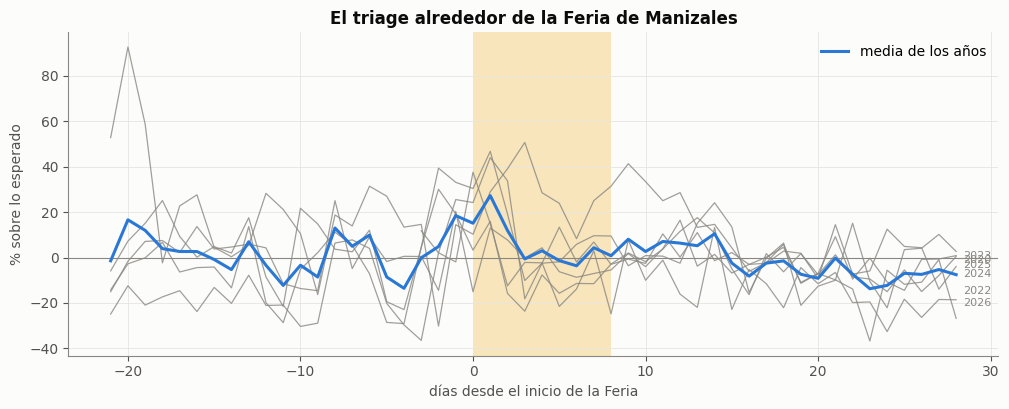

,antes (−21 a −1),Feria (0 a 8),después (9 a 28)
2020,13.1,11.6,-0.1
2022,19.5,27.3,1.2
2023,1.3,-2.0,0.2
2024,5.3,-7.7,-2.4
2025,-2.3,11.0,-1.2
2026,-15.4,-2.4,-13.3
media,3.6,6.3,-2.6


In [7]:
ventana = range(-21, 29)
curvas = {}
for _, f in ferias.iterrows():
    ini = pd.Timestamp(f.fecha_inicio)
    s = D.res.reindex([ini + pd.Timedelta(days=k) for k in ventana])
    s.index = list(ventana)
    curvas[ini.year] = (np.exp(s) - 1) * 100
M = pd.DataFrame(curvas)
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.axvspan(0, 8, color=AMARILLO, alpha=.25, lw=0)
ax.axhline(0, color=MUDO, lw=.8)
for c in M.columns:
    ax.plot(M.index, M[c], color=MUDO, lw=.9, alpha=.8)
    ax.text(M.index[-1] + .4, M[c].iloc[-8:].mean(), str(c), fontsize=8, color=MUDO, va="center")
ax.plot(M.index, M.mean(axis=1), color=AZUL, lw=2.2, label="media de los años")
ax.set_xlabel("días desde el inicio de la Feria"); ax.set_ylabel("% sobre lo esperado")
ax.set_title("El triage alrededor de la Feria de Manizales")
ax.legend(loc="upper right")
plt.show()
res = pd.DataFrame({"antes (−21 a −1)": M.loc[-21:-1].mean(), "Feria (0 a 8)": M.loc[0:8].mean(),
                    "después (9 a 28)": M.loc[9:28].mean()}).round(1)
res.loc["media"] = res.mean().round(1)
res


## Lectura

> **Corrección del 2026-09-28.** Mirando solo el total, la Feria no se separa del regreso de vacaciones. **Mirando su huella, sí.** En `07_mecanismos.ipynb`, los días 0-4 de la Feria traen **SOAT +37 % contra +12 %** de otros regresos, y **particulares +61 % contra +29 %**.

**En el total, el efecto de la Feria no se sostiene de un año a otro.**

| | antes | Feria | después |
|---|---|---|---|
| media de los años | +3,6 % | +6,3 % | −2,6 % |
| 2022 | +19,5 | **+27,3** | +1,2 |
| 2024 | +5,3 | **−7,7** | −2,4 |
| 2025 | −2,3 | **+11,0** | −1,2 |
| 2026 | −15,4 | **−2,4** | −13,3 |

- La media sube un poco en los primeros días de la Feria. Pero **la diferencia entre años (de
  −8 % a +27 %) es mucho mayor que la media**, y el día a día oscila ±30 %.
- **El problema es de diseño, no de datos.** La Feria cae siempre en las dos primeras semanas
  de enero, sobre el regreso de vacaciones y el fin de la temporada navideña. No hay ningún
  año «sin Feria» con el que comparar: 2021 se canceló, pero fue año de COVID. Con este diseño
  su efecto **no se puede separar del calendario**.
- Si interesa medirla, habría que buscar una variable que cambie de un año a otro dentro de la
  Feria: asistencia, número de eventos, días de corrida o de conciertos masivos.

---
# 6. El clima: nivel y cambio brusco

Residuo semanal del triage (panel (b) de la sección 3: sin calendario, sin nivel del año, sin estacionalidad) agrupado en quintiles de cuatro variables de clima. Punto = media del quintil; barra = intervalo del 95 %. Si el clima moviera el triage, los puntos formarían una pendiente.

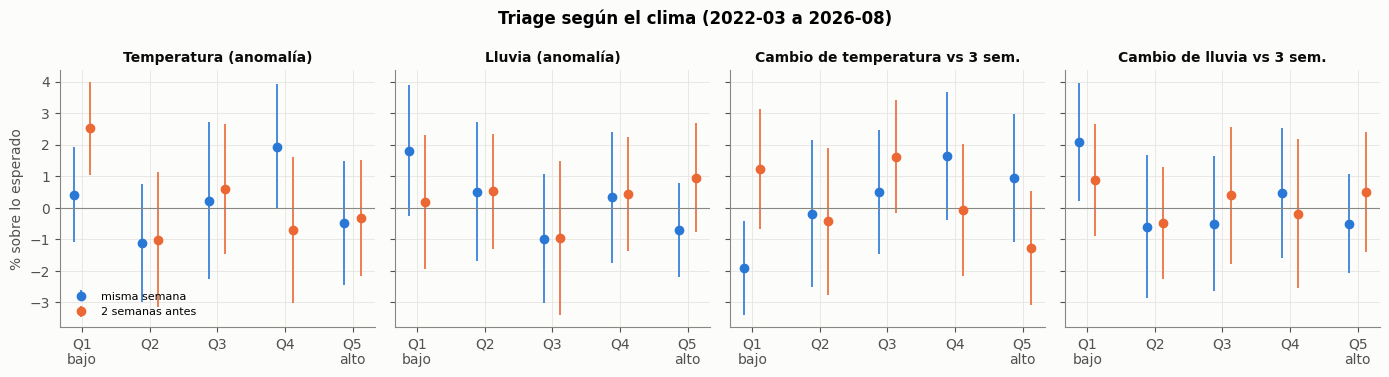

Diferencia Q5 − Q1 (puntos %):
                                 misma semana  2 semanas antes
Cambio de lluvia vs 3 sem.               -2.6             -0.4
Cambio de temperatura vs 3 sem.           2.9             -2.5
Lluvia (anomalía)                        -2.5              0.8
Temperatura (anomalía)                   -0.9             -2.8


In [8]:
vars_clima = ["Temperatura (anomalía)", "Lluvia (anomalía)", "Cambio de temperatura vs 3 sem.", "Cambio de lluvia vs 3 sem."]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
resumen = {}
for ax, v in zip(axes, vars_clima):
    for L, col, dx in [(0, AZUL, -.12), (2, NARANJA, .12)]:
        par = pd.concat([W.res_sin_estac, ext[v].shift(L)], axis=1).dropna()
        q = pd.qcut(par.iloc[:, 1], 5, labels=False)
        g = ((np.exp(par.iloc[:, 0]) - 1) * 100).groupby(q)
        m, e = g.mean(), 1.96 * g.std() / np.sqrt(g.count())
        ax.errorbar(m.index + dx, m.values, yerr=e.values, fmt="o", color=col, ms=6, lw=1.2, capsize=0,
                    label=f"misma semana" if L == 0 else "2 semanas antes")
        resumen[(v, L)] = m.iloc[-1] - m.iloc[0]
    ax.axhline(0, color=MUDO, lw=.8)
    ax.set_xticks(range(5), ["Q1\nbajo", "Q2", "Q3", "Q4", "Q5\nalto"])
    ax.set_title(v, fontsize=10)
axes[0].set_ylabel("% sobre lo esperado")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Triage según el clima (2022-03 a 2026-08)", fontweight="bold")
plt.tight_layout(); plt.show()
print("Diferencia Q5 − Q1 (puntos %):")
print(pd.Series(resumen).unstack().rename(columns={0: "misma semana", 2: "2 semanas antes"}).round(1).to_string())


## Lectura

> **Corrección del 2026-09-28.** Aquí se mide el **nivel** del clima de la semana contra el total. Medido como **cambio brusco** y a 1-2 semanas, el paso de seco a lluvioso sube a los 0-4 años (+22 % con 13 episodios; **+13 % ± 15 con 17 y no significativo tras corregir el pluviómetro el 29-09**), y el enfriamiento y el calentamiento tienen signos coherentes: ver `07_mecanismos.ipynb`, sección 4.

**El triage total no cambia con el nivel semanal del clima de forma visible.**
- En las cuatro variables, la diferencia entre el quintil más alto y el más bajo queda dentro
  de ±3,6 puntos, con intervalos que cruzan el cero.
- No hay pendiente: los puntos suben y bajan sin orden.
- Lo único con dirección es la **lluvia de la misma semana**: −3,6 puntos del quintil más seco
  al más lluvioso. Es coherente con que la lluvia desanime a salir, pero es pequeño y está en
  el borde del ruido.
- El **cambio brusco** de temperatura o de lluvia (la «transición») tampoco muestra pendiente
  a cero ni a dos semanas.


> **Corrección del 2026-09-29 (clima corregido).** Con el pluviómetro arreglado (reportaba 0 mm
> días enteros de oct-2025 a jul-2026), las diferencias entre quintiles quedan dentro de **±2,9
> puntos**, no ±3,6. La lluvia de la misma semana pasa de −3,6 a **−2,5** y el cambio de lluvia de
> −3,0 a −2,6. La lectura no cambia: no hay pendiente.

**Límites.**
- Es clima **observado**. Para pronosticar haría falta el pronosticado, y eso solo puede empeorar
  la señal.
- El pluviómetro solo cubre el 42,9 % de los días (`calendarios/docs/CLIMA.md`), así que la
  lluvia semanal lleva error.
- Una relación no lineal o condicionada (por ejemplo, frío *después* de una sequía larga) no
  la ve un corte en quintiles.

---
# 7. Catástrofes

Residuo diario en los 14 días antes y los 21 después de cada desastre **municipal y con fecha confirmada** del calendario manual. Son pocos: el calendario de desastres es el más pobre de todos, y reemplazarlo por la base de la UNGRD está pendiente.

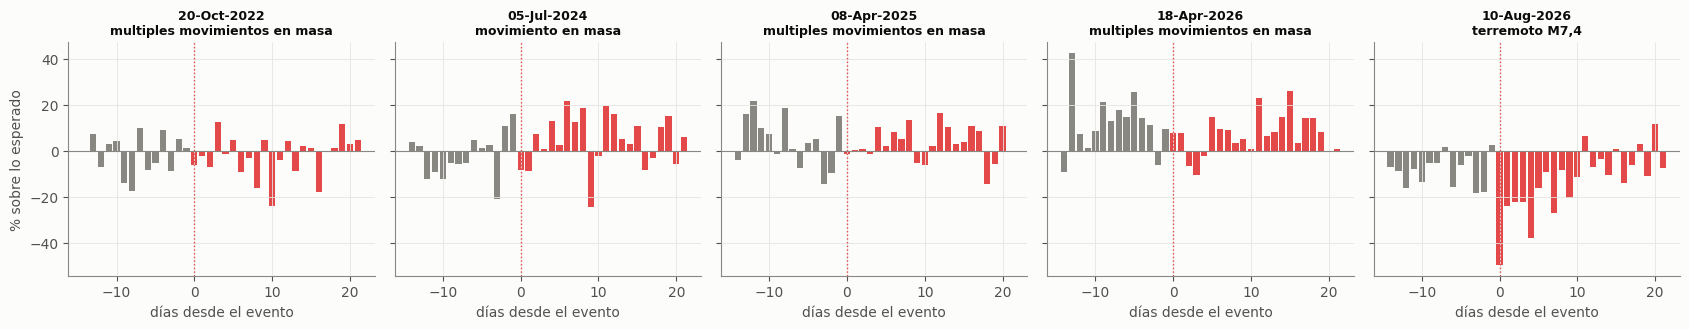

,fecha,evento,14 días antes,7 días después,8-21 días después
0,2022-10-20,multiples_movimientos_en_masa,-1.6,-1.5,-2.9
1,2024-07-05,movimiento_en_masa,-2.2,3.9,4.8
2,2025-04-08,multiples_movimientos_en_masa,4.3,2.6,3.4
3,2026-04-18,multiples_movimientos_en_masa,12.2,2.8,9.0
4,2026-08-10,terremoto_M7.4,-8.7,-26.0,-7.2


In [9]:
ev = desastres[desastres.ambito.isin(["municipal", "institucional"])
               & ~desastres.calidad_dato.isin(["pendiente_verificacion", "fecha_aproximada"])]
ev = ev.drop_duplicates("fecha_inicio")
fig, axes = plt.subplots(1, len(ev), figsize=(3.4 * len(ev), 3.4), sharey=True)
axes = np.atleast_1d(axes)
filas = []
for ax, (_, e) in zip(axes, ev.iterrows()):
    t0 = pd.Timestamp(e.fecha_inicio)
    k = range(-14, 22)
    s = D.res.reindex([t0 + pd.Timedelta(days=i) for i in k]); s.index = list(k)
    p = (np.exp(s) - 1) * 100
    ax.axvline(0, color=ROJO, lw=1, ls=":"); ax.axhline(0, color=MUDO, lw=.8)
    ax.bar(p.index, p.values, color=[ROJO if i >= 0 else MUDO for i in p.index], width=.8)
    ax.set_title(f"{t0:%d-%b-%Y}\n{e.subtipo.replace('_', ' ').replace('M7.4', 'M7,4')[:30]}", fontsize=9)
    ax.set_xlabel("días desde el evento")
    filas.append({"fecha": f"{t0:%Y-%m-%d}", "evento": e.subtipo, "14 días antes": p.loc[-14:-1].mean().round(1),
                  "7 días después": p.loc[0:6].mean().round(1), "8-21 días después": p.loc[7:21].mean().round(1)})
axes[0].set_ylabel("% sobre lo esperado")
plt.tight_layout(); plt.show()
pd.DataFrame(filas)


## Lectura

- **Los deslizamientos no dejan huella en el triage.** La semana siguiente queda entre −1,5 % y
  +3,9 %, dentro del ruido diario (±12 %). Tiene sentido: afectan a pocas personas y sobre todo
  a las vías.
- **El terremoto sí, y hacia abajo.** El día del sismo, −50 %. La primera semana, −26 %; los
  días 8 a 21, −7 %. Una catástrofe grande **reduce** el triage registrado de este hospital.
  Hay varias razones posibles:
  - el propio SES activó expansión hospitalaria y canceló la consulta programada;
  - la gente evita los edificios;
  - hubo vías cerradas;
  - o se registró de otra manera en medio de la emergencia.

  Con los datos no se distingue cuál.
- **Límite serio: es un solo evento.** El calendario de desastres tiene 5 eventos municipales
  con fecha confirmada. Cambiarlo por el consolidado de la UNGRD (80 emergencias en Manizales,
  2019-2025) es lo que daría un número de eventos con el que se pueda decir algo.

---
# 8. Resumen: qué hipótesis salen de aquí

Nada de lo que sigue está probado. Son las hipótesis que este cuaderno sugiere, ordenadas por
lo fuerte que se ve la señal. Cada una se preregistra en `patrones/datos/variables.csv`
**antes** de probarla fuera de muestra contra el control de calendario.

| # | Hipótesis | Lo que la sugiere | Lo que falta para probarla |
|---|---|---|---|
| H1 | **Los cambios en la red de salud** (cierres a EPS, alertas hospitalarias, cambios de criterio) **mueven el triage total más que cualquier otra familia** | Las semanas extremas (nov-2025 a feb-2026, el terremoto, el bloque de 2026) no las explica ningún calendario actual | **Un calendario institucional con fechas**: derecho de petición a la DTSC y noticias de la Alcaldía por API (`FUENTES_EXTERNAS.md`) |
| H2 | **El nivel reciente predice mejor que cualquier variable externa** | La autocorrelación semanal del residuo es +0,62 | Nada: es la base contra la que se mide todo lo demás |
| H3 | **Una catástrofe grande reduce el triage registrado** durante 1-2 semanas | Terremoto: −26 % y −7 % | Más eventos: consolidado de la UNGRD |
| H4 | **La lluvia de la semana baja un poco el triage** (−1 a −4 %) | Mismo signo en las secciones 3 y 6 y en la medición del 28-09 | Pluviómetro con más cobertura, o probarla con acumulados |
| H5 | **Varicela y desnutrición** marcan algo común con el triage, quizá el calendario escolar | r de +0,14 a +0,20 con rezago, pero también en −1 | Calendario escolar oficial (Secretaría de Educación) como control |

**Lo que este cuaderno no podía ver**, y el 07 sí vio, al menos en parte:
- El clima como **cambio brusco con rezago** y por subgrupo: aquí solo se midió el nivel semanal.
- La Feria por su **huella** (SOAT, particulares), no por el total.
- La demanda de consultas de la ciudad como variable adelantada.
- Las vigilancias de salud mental, violencia, intoxicaciones y agresiones: nada por encima del
  azar.

**Siguiente paso natural.** Lo tomó el cuaderno 07. La H1 se confirmó de frente con el asegurador: Nueva EPS explica los escalones de noviembre de 2025 y julio de 2026.